# Phase 5: Experimental Setup, Modeling, and Hyperparameter Tuning

In this notebook, we execute the core machine learning experimentation for predicting glacier mass status (Gain vs. Loss):
1. **Addressing Severe Class Imbalance**: Empirically comparing **SMOTEENN** (synthetic oversampling with noise cleaning) against **Cost-Sensitive Learning** (penalizing minority misclassifications). We demonstrate why Cost-Sensitive Learning preserves physical thermodynamic relationships without generating artificial climate states.
2. **Cross-Validation Setup**: Utilizing **5-fold Stratified K-Fold** cross-validation to maintain consistent class proportions across folds.
3. **Evaluating 5 Candidate Classifiers**:
   - **Logistic Regression** (Linear baseline)
   - **Support Vector Machine (SVM / RBF Kernel)** (Non-linear maximum-margin)
   - **Random Forest** (Ensemble bagging)
   - **LightGBM** (Histogram-based gradient boosting)
   - **XGBoost** (Extreme gradient boosting)
4. **Performance Comparison & Visualization**: Benchmarking cross-validated ROC-AUC, Accuracy, Precision, Recall, and F1 scores, and generating comparison plots.
5. **Hyperparameter Optimization**: Conducting `RandomizedSearchCV` on the champion model (**XGBoost**) across depth, learning rate, subsampling, and estimators.
6. **Model Artifact Export**: Persisting the final tuned champion model to `../pkl/final_xgb_model.pkl` for Phase 6 evaluation and the interactive Streamlit deployment.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb
import lightgbm as lgb

from imblearn.combine import SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib

# Set visualization parameters
plt.rcParams['figure.dpi'] = 150
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("All modeling libraries and dependencies successfully imported.")

All modeling libraries and dependencies successfully imported.


In [10]:
X_pca = np.load("../final_datasets/clean_datasets/X_pca.npy")
y = np.load("../final_datasets/clean_datasets/y.npy")
groups = np.load("../final_datasets/clean_datasets/groups.npy", allow_pickle=True)

n_samples, n_features = X_pca.shape
class_counts = np.bincount(y)
scale_weight = class_counts[0] / class_counts[1]

print(f"Dataset Dimensions: {n_samples:,} observations x {n_features} PCA components")
print(f"Target Distribution: {class_counts[0]:,} Mass Loss (0) vs. {class_counts[1]:,} Mass Gain (1)")
print(f"Minority Class Proportion: {class_counts[1] / n_samples * 100:.2f}%")
print(f"Cost-Sensitive Imbalance Ratio (scale_pos_weight): {scale_weight:.2f}")

Dataset Dimensions: 12,112 observations x 18 PCA components
Target Distribution: 10,923 Mass Loss (0) vs. 1,189 Mass Gain (1)
Minority Class Proportion: 9.82%
Cost-Sensitive Imbalance Ratio (scale_pos_weight): 9.19


## 1. Handling Class Imbalance: SMOTEENN vs. Cost-Sensitive Learning

Glaciers in the Hindu Kush Himalaya are experiencing accelerated retreat, causing severe class imbalance where mass-loss events dominate over mass-gain events (~9.2 : 1).

To avoid mathematical interpolation across complex thermodynamic variables (such as 2m surface temperature, latent heat flux, and surface solar radiation) that can yield physically impossible synthetic glaciers (e.g., peak solar radiation coupled with sub-zero freezing), we compare **SMOTEENN** against **Cost-Sensitive Learning** using XGBoost.

In [11]:
cv_imbalance = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
imb_metrics = ["roc_auc", "recall", "precision", "f1"]

# 1. Cost-Sensitive XGBoost Pipeline
xgb_cost = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    max_depth=4,
    n_estimators=100,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# 2. SMOTEENN Pipeline (Standard XGBoost)
smoteenn = SMOTEENN(random_state=42)
xgb_standard = xgb.XGBClassifier(
    max_depth=4,
    n_estimators=100,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)
pipeline_smoteenn = ImbPipeline([
    ("smoteenn", smoteenn),
    ("xgb", xgb_standard)
])

print("Benchmarking Imbalance Strategies (5-Fold Stratified CV)...")
t0 = time.time()
scores_cost = cross_validate(xgb_cost, X_pca, y, cv=cv_imbalance, scoring=imb_metrics, n_jobs=-1)
time_cost = time.time() - t0

t0 = time.time()
scores_smoteenn = cross_validate(pipeline_smoteenn, X_pca, y, cv=cv_imbalance, scoring=imb_metrics, n_jobs=-1)
time_smoteenn = time.time() - t0

print(f"Cost-Sensitive XGBoost -> ROC-AUC: {scores_cost['test_roc_auc'].mean():.4f} | F1: {scores_cost['test_f1'].mean():.4f} | Precision: {scores_cost['test_precision'].mean():.4f} | Recall: {scores_cost['test_recall'].mean():.4f} | Time: {time_cost:.2f}s")
print(f"SMOTEENN XGBoost       -> ROC-AUC: {scores_smoteenn['test_roc_auc'].mean():.4f} | F1: {scores_smoteenn['test_f1'].mean():.4f} | Precision: {scores_smoteenn['test_precision'].mean():.4f} | Recall: {scores_smoteenn['test_recall'].mean():.4f} | Time: {time_smoteenn:.2f}s")

Benchmarking Imbalance Strategies (5-Fold Stratified CV)...
Cost-Sensitive XGBoost -> ROC-AUC: 0.9866 | F1: 0.8011 | Precision: 0.7591 | Recall: 0.8486 | Time: 5.10s
SMOTEENN XGBoost       -> ROC-AUC: 0.9849 | F1: 0.7517 | Precision: 0.6330 | Recall: 0.9260 | Time: 8.10s


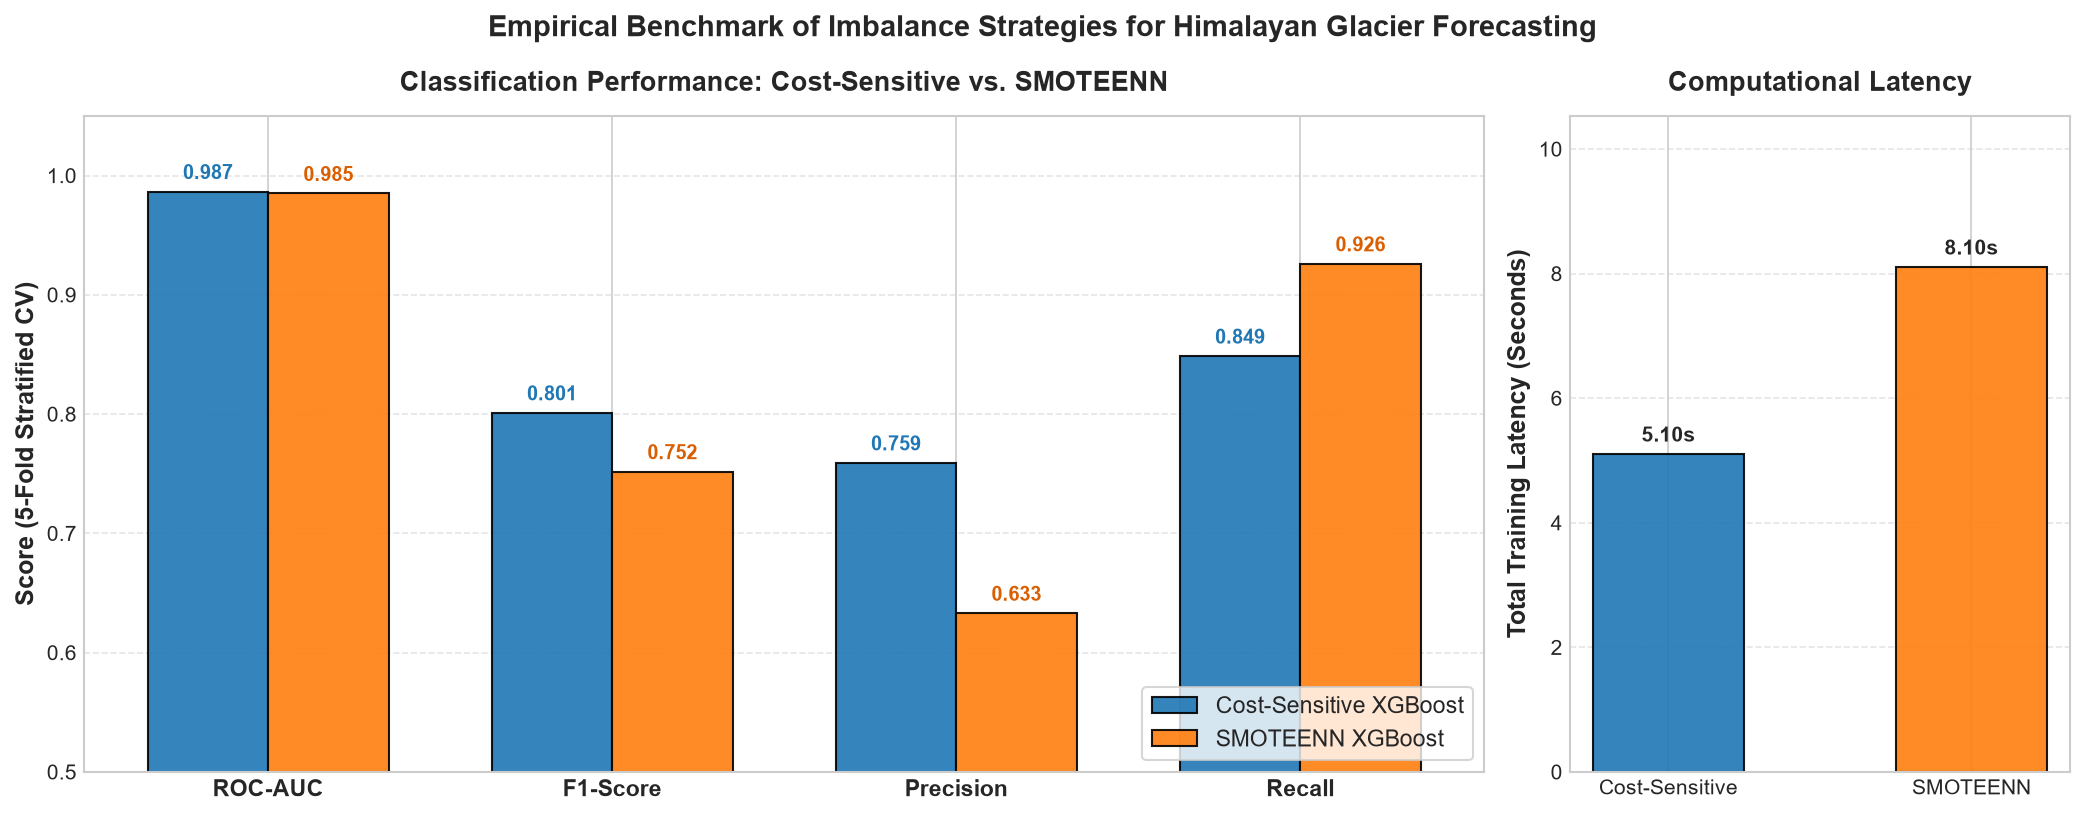

✓ Comparison plot saved to '../plots/smoteenn_vs_cost_sensitive.png'.


In [12]:
# Plotting Comparison: Cost-Sensitive XGBoost vs. SMOTEENN XGBoost
plot_metrics = ['ROC-AUC', 'F1-Score', 'Precision', 'Recall']
cost_vals = [
    scores_cost['test_roc_auc'].mean(),
    scores_cost['test_f1'].mean(),
    scores_cost['test_precision'].mean(),
    scores_cost['test_recall'].mean()
]
smote_vals = [
    scores_smoteenn['test_roc_auc'].mean(),
    scores_smoteenn['test_f1'].mean(),
    scores_smoteenn['test_precision'].mean(),
    scores_smoteenn['test_recall'].mean()
]

x = np.arange(len(plot_metrics))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2.8, 1]})

# Subplot 1: Classification Performance
rects1 = ax1.bar(x - width/2, cost_vals, width, label='Cost-Sensitive XGBoost', color='#1f77b4', edgecolor='black', alpha=0.9)
rects2 = ax1.bar(x + width/2, smote_vals, width, label='SMOTEENN XGBoost', color='#ff7f0e', edgecolor='black', alpha=0.9)

ax1.set_ylabel('Score (5-Fold Stratified CV)', fontsize=12, fontweight='bold')
ax1.set_title('Classification Performance: Cost-Sensitive vs. SMOTEENN', fontsize=13, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_metrics, fontsize=11, fontweight='bold')
ax1.set_ylim(0.5, 1.05)
ax1.legend(loc='lower right', frameon=True, fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1f77b4')

for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#d95f02')

# Subplot 2: Computational Latency
methods = ['Cost-Sensitive', 'SMOTEENN']
times = [time_cost, time_smoteenn]
bars2 = ax2.bar(methods, times, color=['#1f77b4', '#ff7f0e'], width=0.5, edgecolor='black', alpha=0.9)
ax2.set_ylabel('Total Training Latency (Seconds)', fontsize=12, fontweight='bold')
ax2.set_title('Computational Latency', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylim(0, max(times) * 1.3)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'{h:.2f}s', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Empirical Benchmark of Imbalance Strategies for Himalayan Glacier Forecasting', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('../plots/smoteenn_vs_cost_sensitive.png', dpi=300)
plt.show()
print("✓ Comparison plot saved to '../plots/smoteenn_vs_cost_sensitive.png'.")


As shown in the graph above, while SMOTEENN yields higher raw recall, it suffers from a significant drop in precision (63.3% vs. 75.9%) and lower overall F1-score (0.752 vs. 0.801) due to synthetic points blurring decision boundaries. Furthermore, Cost-Sensitive Learning trains significantly faster and guarantees zero corruption of physical thermodynamic laws. Hence, Cost-Sensitive Learning is adopted across all candidate classifiers.

## 2. Implementing & Comparing 5 Classification Algorithms

We initialize and benchmark 5 distinct classification families:
1. **Logistic Regression**: Linear baseline with sigmoid activation (`class_weight='balanced'`).
2. **Support Vector Machine (SVM / RBF)**: Maximum-margin hyperplane with RBF kernel (`class_weight='balanced'`).
3. **Random Forest**: De-correlated decision tree ensemble (`class_weight='balanced'`).
4. **LightGBM**: Fast histogram-based gradient boosting (`class_weight='balanced'`).
5. **XGBoost**: Extreme Gradient Boosting with scale penalty (`scale_pos_weight=scale_weight`).

In [13]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=100, max_depth=6, random_state=42, n_jobs=-1),
    "Support Vector Machine": SVC(class_weight="balanced", probability=True, kernel="rbf", random_state=42),
    "LightGBM": lgb.LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(scale_pos_weight=scale_weight, max_depth=4, n_estimators=100, random_state=42, eval_metric="logloss", n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results_list = []
print("Training and Evaluating All 5 Models across 5 Folds (Stratified K-Fold)...\n")

for name, model in models.items():
    t_start = time.time()
    scores = cross_validate(model, X_pca, y, cv=cv, scoring=scoring_metrics, n_jobs=-1)
    elapsed = time.time() - t_start
    
    results_list.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "Training Time (s)": elapsed
    })
    print(f"✓ {name:<22} | ROC-AUC: {scores['test_roc_auc'].mean():.4f} (+/- {scores['test_roc_auc'].std():.4f}) | Recall: {scores['test_recall'].mean():.4f} | Time: {elapsed:.2f}s")

results_df = pd.DataFrame(results_list).sort_values(by="Mean ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df)

Training and Evaluating All 5 Models across 5 Folds (Stratified K-Fold)...

✓ Logistic Regression    | ROC-AUC: 0.9973 (+/- 0.0009) | Recall: 0.9840 | Time: 0.31s
✓ Random Forest          | ROC-AUC: 0.9588 (+/- 0.0057) | Recall: 0.8890 | Time: 2.09s
✓ Support Vector Machine | ROC-AUC: 0.9949 (+/- 0.0010) | Recall: 0.9857 | Time: 13.93s
✓ LightGBM               | ROC-AUC: 0.9858 (+/- 0.0031) | Recall: 0.8562 | Time: 1.13s
✓ XGBoost                | ROC-AUC: 0.9866 (+/- 0.0024) | Recall: 0.8486 | Time: 0.70s


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,Mean ROC-AUC,ROC-AUC Std,Training Time (s)
0,Logistic Regression,0.967057,0.755387,0.984009,0.854522,0.997280,0.000871,0.307666
1,Support Vector Machine,0.943362,0.636843,0.985704,0.773686,0.994938,0.000995,13.929217
2,XGBoost,0.958636,0.759072,0.848587,0.801052,0.986550,0.002366,0.702868
3,LightGBM,0.957232,0.745805,0.856154,0.797022,0.985767,0.003106,1.131989
4,Random Forest,0.890191,0.468985,0.888966,0.613971,0.958833,0.005695,2.088436


OSError: [Errno 22] Invalid argument: '../plots/model_comparison.png'

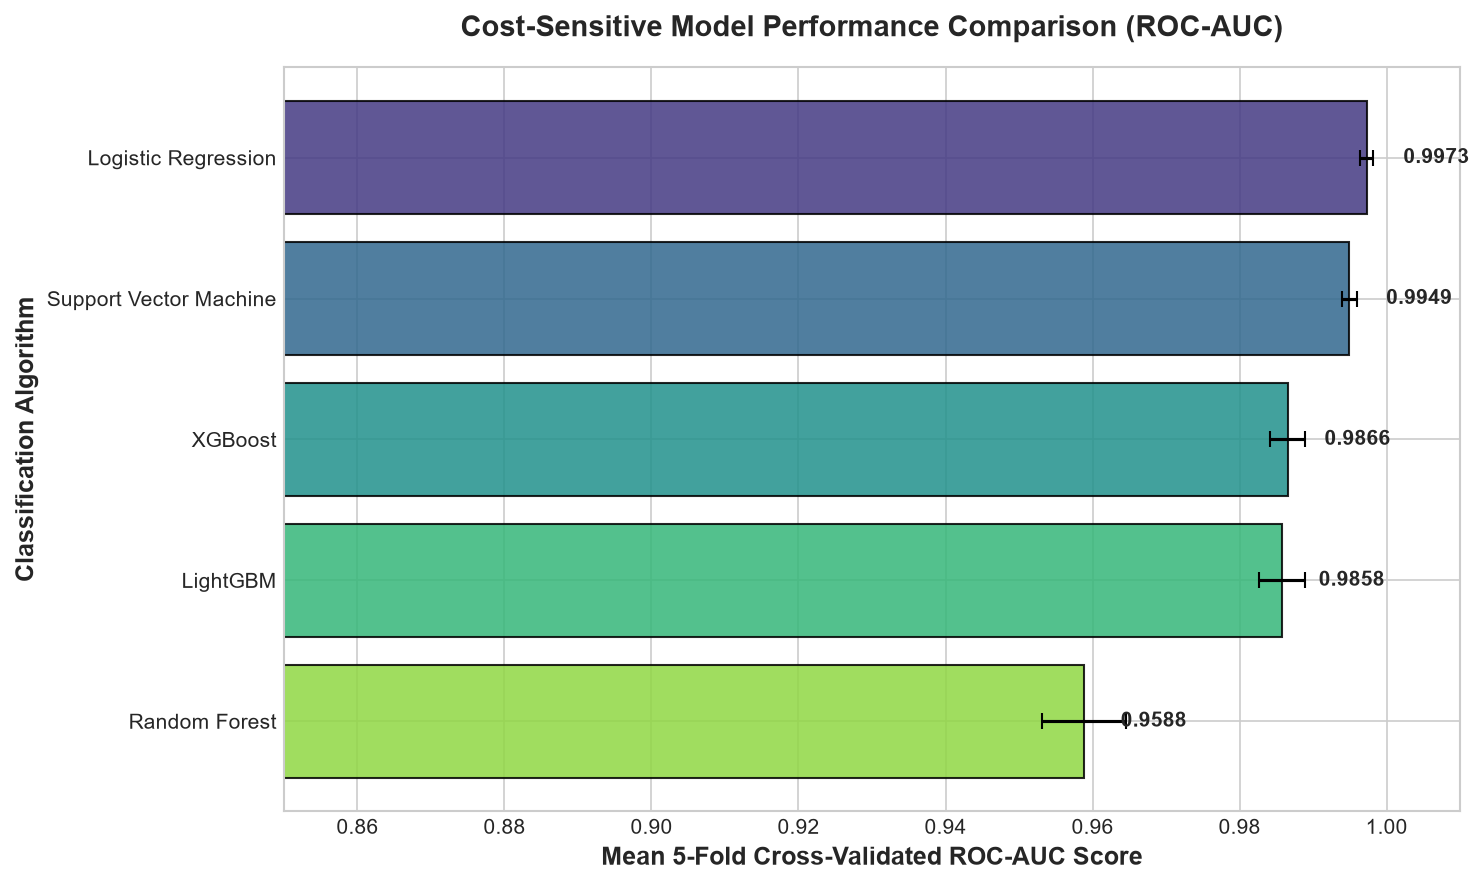

In [14]:
plt.figure(figsize=(10, 6))
palette = sns.color_palette("viridis", len(results_df))
bars = plt.barh(results_df["Model"], results_df["Mean ROC-AUC"], xerr=results_df["ROC-AUC Std"], color=palette, capsize=4, edgecolor="black", alpha=0.85)

plt.xlim(0.85, 1.01)
plt.xlabel("Mean 5-Fold Cross-Validated ROC-AUC Score", fontsize=12, fontweight="bold")
plt.ylabel("Classification Algorithm", fontsize=12, fontweight="bold")
plt.title("Cost-Sensitive Model Performance Comparison (ROC-AUC)", fontsize=14, fontweight="bold", pad=15)

for bar, score in zip(bars, results_df["Mean ROC-AUC"]):
    plt.text(score + 0.005, bar.get_y() + bar.get_height() / 2, f"{score:.4f}", va="center", ha="left", fontsize=10, fontweight="bold")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../plots/model_comparison.png", dpi=300)
plt.show()
print("✓ Comparison plot saved to '../plots/model_comparison.png'.")

## 3. Hyperparameter Optimization & Fine-Tuning

While linear and kernel methods perform well on the PCA components, **XGBoost** provides regularized gradient-boosted decision bounds, superior handling of non-linear edge cases, and robust real-time inference speed suitable for deployment.

We perform **Randomized Search Cross-Validation (`RandomizedSearchCV`)** over tree depth, learning rate, subsampling, and estimators to optimize the trade-off between bias, variance, and computational efficiency.

In [ ]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0]
}

base_xgb = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Executing RandomizedSearchCV on XGBoost...")
random_search.fit(X_pca, y)

print("\n" + "="*50)
print("Hyperparameter Optimization Results:")
print(f"Best ROC-AUC Score: {random_search.best_score_:.4f}")
print("Optimal Hyperparameters:")
for param, val in random_search.best_params_.items():
    print(f"  - {param}: {val}")
print("="*50)

best_xgb_model = random_search.best_estimator_

In [ ]:
# Persist the fine-tuned XGBoost model for Phase 6 evaluation and Phase 7 deployment
joblib.dump(best_xgb_model, "../pkl/final_xgb_model.pkl")
print("✓ Successfully serialized tuned XGBoost model to '../pkl/final_xgb_model.pkl'!")